# Proyecto de Aula — Minería de Datos en Salud
## Predicción de diabetes mediante técnicas de Machine Learning

**Integrantes:** Geiser Guerrero y Beny Niebles  
**Asignatura:** Minería de Datos  
**Docente:** José Escorcia-Gutiérrez  

### Objetivo
Explorar un conjunto de datos con variables clínicas y demográficas y construir modelos de clasificación para estimar la variable Outcome. Este ejercicio es académico y no constituye una herramienta de diagnóstico médico.

## 1. Contexto y cambio del conjunto de datos

El proyecto conserva la pregunta de investigación del primer avance: ¿en qué medida las variables clínicas y demográficas disponibles permiten clasificar los registros según la variable Outcome? Se trata de un ejercicio de clasificación supervisada, no de una herramienta de diagnóstico médico.

En el primer avance se planteó utilizar el Pima Indians Diabetes Dataset. Debido a que no se conservó una copia local del archivo original y el enlace utilizado inicialmente dejó de estar disponible, para este avance se incorporó otro archivo CSV con variables de nombres similares. El archivo actual se atribuye en el registro del grupo a Kaggle: https://www.kaggle.com/datasets/vikasukani/diabetes-data-set. La sustitución se declara para mantener la trazabilidad del proyecto; no se asume que el archivo sea idéntico al dataset del primer avance.

La variable objetivo es Outcome (0 o 1). Los valores se interpretan únicamente según la codificación del dataset, no como una confirmación clínica individual. La fuente, la composición de los registros y la forma en que se recopilaron los datos son limitaciones que deben tenerse presentes al interpretar los resultados.

## 2. Librerías y carga de datos


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

DATA_PATH = "diabetes-dataset.csv"
df = pd.read_csv(DATA_PATH)

print(f"Dimensiones del conjunto de datos: {df.shape[0]} filas y {df.shape[1]} columnas")
display(df.head())

Dimensiones del conjunto de datos: 2000 filas y 9 columnas


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,2,138,62,35,0,33.6,0.127,47,1
1,0,84,82,31,125,38.2,0.233,23,0
2,0,145,0,0,0,44.2,0.630,31,1
3,0,135,68,42,250,42.3,0.365,24,1
4,1,139,62,41,480,40.7,0.536,21,0


## 3. Descripción de las variables

| Variable | Descripción general | Tipo |
|---|---|---|
| `Pregnancies` | Número de embarazos registrados | Numérica |
| `Glucose` | Medición de glucosa | Numérica |
| `BloodPressure` | Presión arterial | Numérica |
| `SkinThickness` | Medición del pliegue cutáneo | Numérica |
| `Insulin` | Medición de insulina | Numérica |
| `BMI` | Índice de masa corporal | Numérica |
| `DiabetesPedigreeFunction` | Indicador relacionado con antecedentes familiares | Numérica |
| `Age` | Edad | Numérica |
| `Outcome` | Variable objetivo: 0 o 1 | Binaria |


## 4. Inspección inicial

In [ ]:
display(df.info())
display(df.describe().T)
print("\nValores nulos por columna:")
display(df.isna().sum().to_frame("valores_nulos"))
print("\nRegistros duplicados exactos:", df.duplicated().sum())
print("\nDistribución de Outcome:")
display(df["Outcome"].value_counts(dropna=False).sort_index().to_frame("cantidad"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               2000 non-null   int64  
 1   Glucose                   2000 non-null   int64  
 2   BloodPressure             2000 non-null   int64  
 3   SkinThickness             2000 non-null   int64  
 4   Insulin                   2000 non-null   int64  
 5   BMI                       2000 non-null   float64
 6   DiabetesPedigreeFunction  2000 non-null   float64
 7   Age                       2000 non-null   int64  
 8   Outcome                   2000 non-null   int64  
dtypes: float64(2), int64(7)
memory usage: 140.8 KB


None

,count,mean,std,min,25%,50%,75%,max
Pregnancies,2000.0,3.70350,3.306063,0.000,1.000,3.000,6.000,17.00
Glucose,2000.0,121.18250,32.068636,0.000,99.000,117.000,141.000,199.00
BloodPressure,2000.0,69.14550,19.188315,0.000,63.500,72.000,80.000,122.00
SkinThickness,2000.0,20.93500,16.103243,0.000,0.000,23.000,32.000,110.00
Insulin,2000.0,80.25400,111.180534,0.000,0.000,40.000,130.000,744.00
BMI,2000.0,32.19300,8.149901,0.000,27.375,32.300,36.800,80.60
DiabetesPedigreeFunction,2000.0,0.47093,0.323553,0.078,0.244,0.376,0.624,2.42
Age,2000.0,33.09050,11.786423,21.000,24.000,29.000,40.000,81.00
Outcome,2000.0,0.34200,0.474498,0.000,0.000,0.000,1.000,1.00



Valores nulos por columna:


,valores_nulos
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0



Registros duplicados exactos: 1256

Distribución de Outcome:


,cantidad
Outcome,
0,1316
1,684


## 5. Análisis exploratorio de datos (EDA)

Primero se revisan la distribución de la variable objetivo, las distribuciones de las variables numéricas y las relaciones entre variables. Estas gráficas permiten identificar patrones y posibles problemas de calidad.

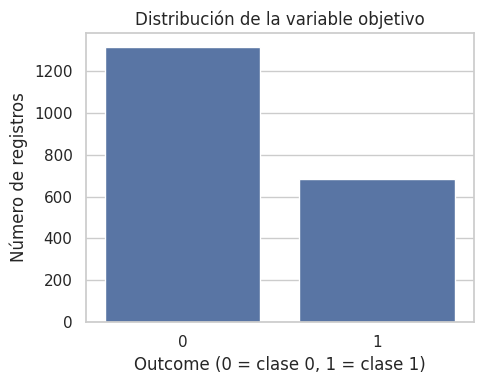

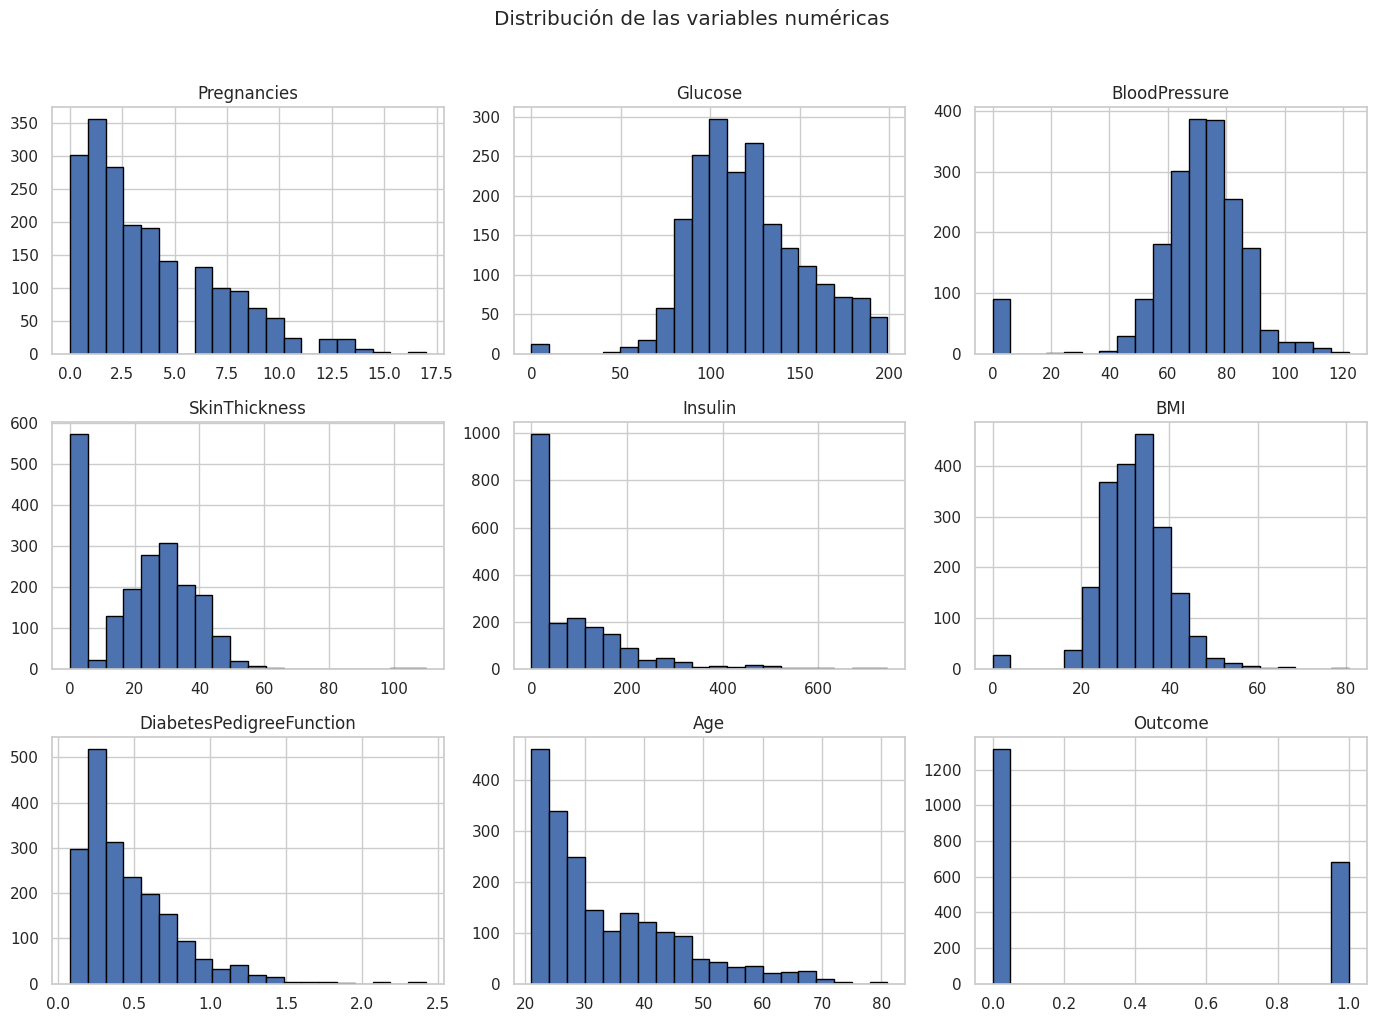

In [ ]:
if "Outcome" not in df.columns:
    raise ValueError("No se encontró la columna objetivo 'Outcome'.")

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="Outcome", color="#4C72B0")
plt.title("Distribución de la variable objetivo")
plt.xlabel("Outcome (0 = clase 0, 1 = clase 1)")
plt.ylabel("Número de registros")
plt.tight_layout()
plt.show()

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
df[numeric_cols].hist(figsize=(14, 10), bins=20, edgecolor="black")
plt.suptitle("Distribución de las variables numéricas", y=1.02)
plt.tight_layout()
plt.show()

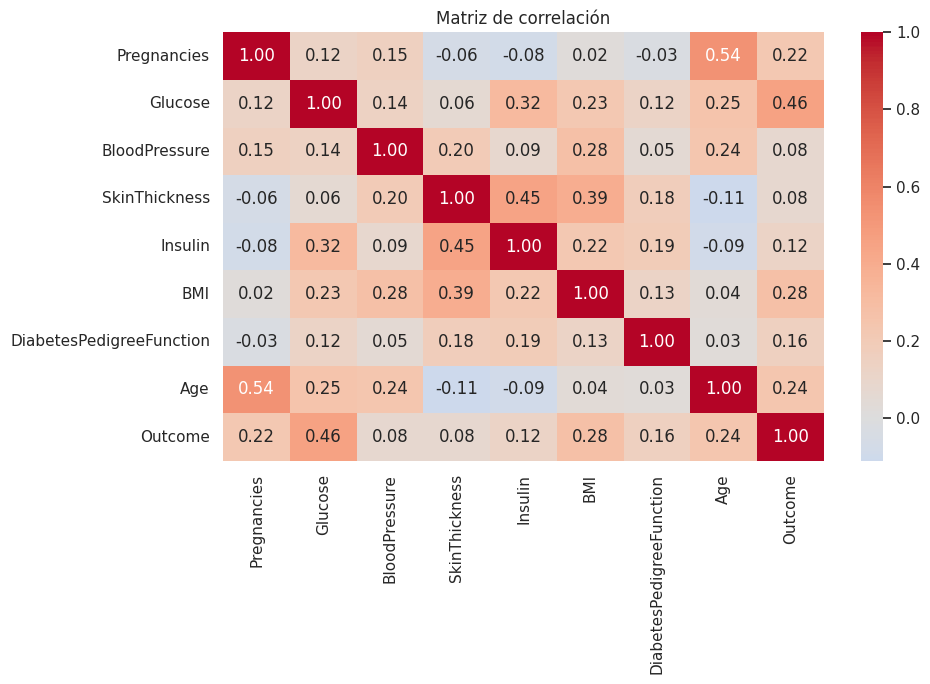

In [ ]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0)
plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

## 6. Preparación y calidad de los datos

Se revisan las filas duplicadas y los ceros en variables donde un valor cero puede representar una medición ausente en este tipo de dataset (`Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` y `BMI`). Antes de aplicar esta regla, se conserva una copia del archivo original.

Debido a que el archivo actual presenta numerosos registros duplicados, se eliminarán las filas idénticas antes de dividir los datos. Esto reduce el riesgo de que copias del mismo registro aparezcan tanto en entrenamiento como en prueba y produzcan métricas demasiado optimistas.

In [ ]:
df_work = df.copy()

# Validaciones básicas de estructura
required_cols = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
]
missing_cols = [c for c in required_cols if c not in df_work.columns]
if missing_cols:
    raise ValueError(f"Faltan columnas esperadas: {missing_cols}")

df_work = df_work[required_cols].copy()
print("Filas antes de quitar duplicados:", len(df_work))
print("Duplicados exactos:", df_work.duplicated().sum())
df_work = df_work.drop_duplicates().reset_index(drop=True)
print("Filas después de quitar duplicados:", len(df_work))

# Reemplazar ceros usados potencialmente como ausencia de medición
zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
for col in zero_as_missing:
    df_work[col] = df_work[col].replace(0, np.nan)

print("\nNulos después de revisar ceros:")
display(df_work.isna().sum().to_frame("nulos"))
print("\nDistribución de Outcome tras quitar duplicados:")
display(df_work["Outcome"].value_counts().sort_index().to_frame("cantidad"))

Filas antes de quitar duplicados: 2000
Duplicados exactos: 1256
Filas después de quitar duplicados: 744

Nulos después de revisar ceros:


,nulos
Pregnancies,0
Glucose,5
BloodPressure,34
SkinThickness,215
Insulin,359
BMI,10
DiabetesPedigreeFunction,0
Age,0
Outcome,0



Distribución de Outcome tras quitar duplicados:


,cantidad
Outcome,
0,491
1,253


## 7. Separación de variables y división entrenamiento/prueba

Se usa una división estratificada para conservar aproximadamente la proporción de las clases. La imputación y el escalado se ajustan dentro de un `Pipeline`, utilizando únicamente los datos de entrenamiento para reducir el riesgo de fuga de información.

In [ ]:
X = df_work.drop(columns="Outcome")
y = df_work["Outcome"].astype(int)

if not set(y.unique()).issubset({0, 1}):
    raise ValueError("La variable Outcome debe contener únicamente las clases 0 y 1.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

numeric_features = X.columns.tolist()
preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Tamaño de entrenamiento:", X_train.shape)
print("Tamaño de prueba:", X_test.shape)
print("\nDistribución de clases en entrenamiento:")
display(y_train.value_counts(normalize=True).sort_index().to_frame("proporción"))
print("\nDistribución de clases en prueba:")
display(y_test.value_counts(normalize=True).sort_index().to_frame("proporción"))

Tamaño de entrenamiento: (595, 8)
Tamaño de prueba: (149, 8)

Distribución de clases en entrenamiento:


,proporción
Outcome,
0,0.660504
1,0.339496



Distribución de clases en prueba:


,proporción
Outcome,
0,0.657718
1,0.342282


## 8. Entrenamiento de modelos

Se entrenan dos clasificadores de referencia: **Regresión Logística** y **Bosque Aleatorio (Random Forest)**. Son modelos iniciales para comparar; no se presupone que alguno sea superior antes de evaluar sus resultados.

In [ ]:
models = {
    "Regresión logística": LogisticRegression(max_iter=2000, random_state=42),
    "Bosque aleatorio": RandomForestClassifier(
        n_estimators=300, random_state=42, class_weight="balanced"
    )
}

fitted_models = {}
predictions = {}
results = []

for name, estimator in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    fitted_models[name] = pipe
    predictions[name] = y_pred
    results.append({
        "Modelo": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values("F1-score", ascending=False)
display(results_df.round(3))

,Modelo,Accuracy,Precision,Recall,F1-score
0,Regresión logística,0.765,0.722,0.510,0.598
1,Bosque aleatorio,0.752,0.675,0.529,0.593


## 9. Evaluación detallada

Se presentan el reporte de clasificación y la matriz de confusión de cada modelo. La precisión, el recall y el F1-score ayudan a complementar la exactitud (`accuracy`), especialmente cuando las clases no están equilibradas.

Regresión logística
              precision    recall  f1-score   support

   Outcome 0       0.78      0.90      0.83        98
   Outcome 1       0.72      0.51      0.60        51

    accuracy                           0.77       149
   macro avg       0.75      0.70      0.72       149
weighted avg       0.76      0.77      0.75       149



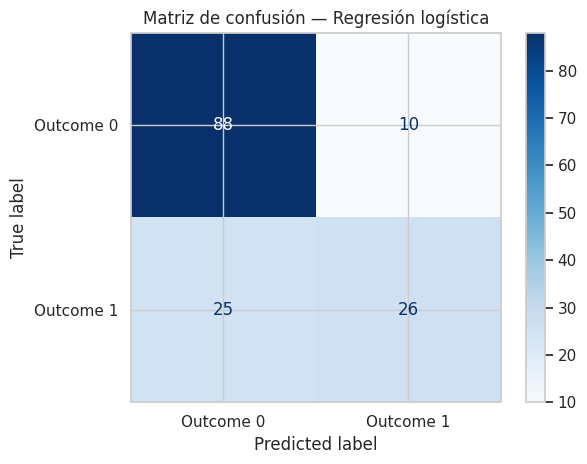

Bosque aleatorio
              precision    recall  f1-score   support

   Outcome 0       0.78      0.87      0.82        98
   Outcome 1       0.68      0.53      0.59        51

    accuracy                           0.75       149
   macro avg       0.73      0.70      0.71       149
weighted avg       0.74      0.75      0.74       149



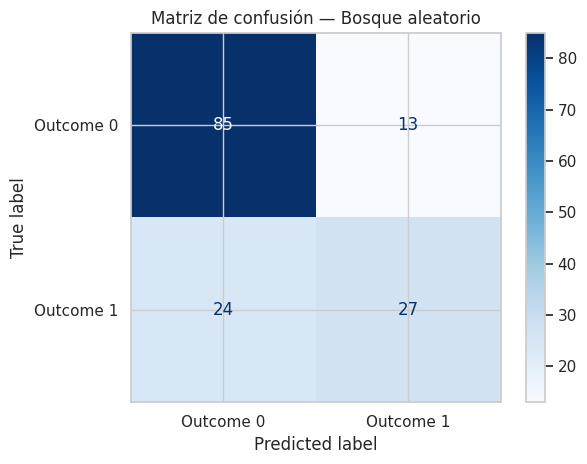

In [ ]:
for name, y_pred in predictions.items():
    print("=" * 70)
    print(name)
    print(classification_report(y_test, y_pred, zero_division=0,
                                target_names=["Outcome 0", "Outcome 1"]))
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                  display_labels=["Outcome 0", "Outcome 1"])
    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Matriz de confusión — {name}")
    plt.tight_layout()
    plt.show()

## 10. Comparación visual de los modelos

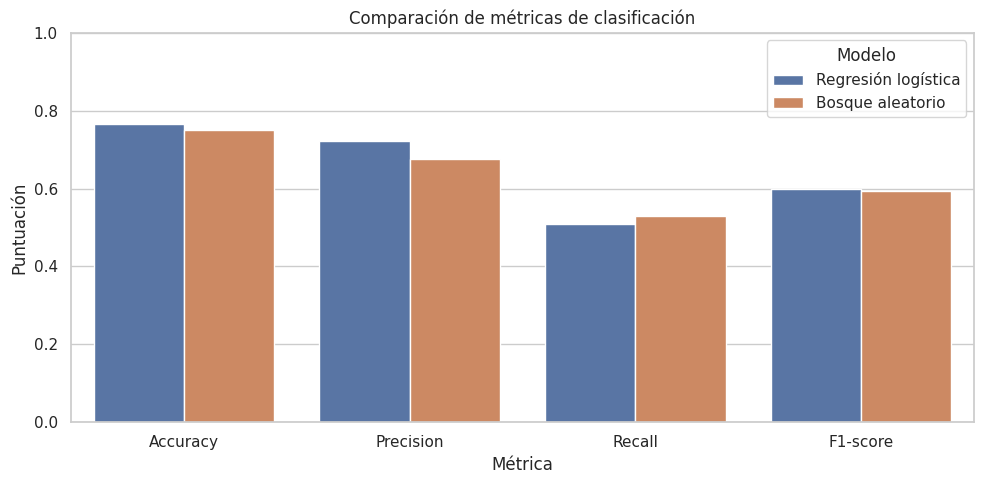

In [ ]:
metrics_long = results_df.melt(
    id_vars="Modelo",
    value_vars=["Accuracy", "Precision", "Recall", "F1-score"],
    var_name="Métrica",
    value_name="Valor"
)
plt.figure(figsize=(10, 5))
sns.barplot(data=metrics_long, x="Métrica", y="Valor", hue="Modelo", palette=["#4C72B0", "#DD8452"])
plt.ylim(0, 1)
plt.title("Comparación de métricas de clasificación")
plt.ylabel("Puntuación")
plt.tight_layout()
plt.show()

## 11. Interpretación de resultados


Comparación del desempeño
La regresión logística obtuvo el mayor accuracy (0,765) y el mayor F1-score (0,598). Su precisión para la clase positiva fue 0,722 y su recall fue 0,510. El bosque aleatorio obtuvo un accuracy de 0,752, precisión de 0,675, recall de 0,529 y F1-score de 0,593. Por tanto, la regresión logística presenta una ventaja pequeña en exactitud, precisión y F1; el bosque aleatorio recupera una proporción ligeramente mayor de los positivos.
Errores de clasificación
En el conjunto de prueba hubo 149 registros: 98 de la clase Outcome 0 y 51 de Outcome 1.
- Regresión logística: para la clase positiva, el recall de 0,51 significa que identificó aproximadamente 26 de los 51 registros positivos. La matriz de confusión muestra 25 falsos negativos y 10 falsos positivos.
- Bosque aleatorio: identificó aproximadamente 27 de los 51 registros positivos. La matriz de confusión muestra 24 falsos negativos y 13 falsos positivos.
En un problema de salud, los falsos negativos son especialmente relevantes porque corresponden a registros positivos que el modelo clasificó como negativos. Aun así, la elección del modelo no debe basarse en una sola métrica: depende del propósito, de los costos de los errores y de una validación más amplia. Ninguno de estos resultados demuestra que el modelo sea apto para tomar decisiones médicas.
Calidad de los datos y limitaciones
El archivo inicial contiene 2.000 filas y no presenta valores nulos explícitos, pero se detectaron 1.256 filas duplicadas exactas. Tras eliminarlas quedaron 744 registros; la división estratificada utilizó 595 para entrenamiento y 149 para prueba. Además, se trataron como posibles mediciones ausentes los ceros de Glucose, BloodPressure, SkinThickness, Insulin y BMI, y se imputaron con la mediana dentro del flujo de preprocesamiento.

La proporción de duplicados es alta y debe verificarse con la fuente original. No se puede concluir, solo a partir de las filas repetidas, si son errores de captura o registros legítimos. También se debe confirmar la procedencia y el significado de las variables del dataset sustituto. Finalmente, la prueba corresponde a una sola partición aleatoria; no se realizó validación externa ni se evaluó el modelo con una población independiente.

## 12. Conclusiones preliminares

La exploración permite revisar la calidad de los datos y construir una comparación inicial entre dos modelos de clasificación. Se entrenaron y evaluaron dos modelos de clasificación para estimar la variable Outcome: regresión logística y bosque aleatorio. La regresión logística obtuvo una exactitud del 76,5 % y un F1-score del 59,8 %, mientras que el bosque aleatorio alcanzó una exactitud del 75,2 % y un F1-score del 59,3 %. El bosque aleatorio presentó un recall ligeramente superior para la clase positiva. Estos resultados constituyen una evaluación preliminar y no permiten afirmar que los modelos estén preparados para realizar diagnósticos médicos. Además, la cantidad de registros duplicados eliminados y la procedencia del conjunto de datos deben analizarse, ya que pueden influir en la interpretación de los resultados.

## 13. Registro de uso de inteligencia artificial

Herramientas utilizadas
- ChatGPT: apoyo para organizar el notebook, explicar pasos de análisis, revisar la redacción y proponer interpretaciones que después se contrastaron con las salidas del código.
- Claude: apoyo para complementar y revisar partes del código y del proceso de preparación de datos.
Propósito y contexto
Se recurrió a estas herramientas para apoyar la comprensión de los datos y del código, además de reconstruir el flujo de trabajo después de perder el archivo CSV usado en el primer avance. El grupo incorporó un dataset alternativo porque el enlace del archivo anterior no permitió recuperar la copia que se había utilizado. La fuente del archivo actual se registró como https://www.kaggle.com/datasets/vikasukani/diabetes-data-set.
Evaluación crítica y ajustes
Las respuestas de IA se trataron como sugerencias, no como evidencia. Se contrastaron las métricas con las salidas ejecutadas del notebook. La comparación que se presenta aquí utiliza los valores reales impresos por el código: regresión logística (accuracy 0,765; precision 0,722; recall 0,510; F1-score 0,598) y bosque aleatorio (accuracy 0,752; precision 0,675; recall 0,529; F1-score 0,593). También se dejó explícita la presencia de 1.256 duplicados y la necesidad de verificar la procedencia del dataset. No se debe afirmar que la fuente, los datos o las referencias han sido validados por IA.
Prompts y responsabilidad del grupo
Las instrucciones utilizadas consistieron, entre otras, en solicitar ayuda para organizar el notebook de clasificación de diabetes, revisar el preprocesamiento, comparar las métricas de dos modelos y mejorar la redacción de las interpretaciones. Para cumplir estrictamente la guía de la asignatura, el grupo debe anexar o transcribir los prompts completos que efectivamente utilizó en cada herramienta; no se reconstruyen aquí como si fueran citas literales.

Como integrantes, declaramos que debemos revisar el código, verificar que las interpretaciones coincidan con las salidas y comprobar la exactitud de las referencias. Asumimos la responsabilidad académica por el contenido final entregado.

## 14. Referencias

- Scikit-learn. *User Guide*. https://scikit-learn.org/stable/user_guide.html
- Pandas. *Getting started*. https://pandas.pydata.org/docs/getting_started/index.html
- Matplotlib. *Usage guide*. https://matplotlib.org/stable/users/index.html
- Seaborn. *User guide and tutorial*. https://seaborn.pydata.org/tutorial.html

- Dataset. *kaggle* https://www.kaggle.com/datasets/vikasukani/diabetes-data-set

## 15. Revisión y despliegue del tercer corte

Se recuperó el CSV desde la fuente registrada y se reprodujeron las métricas originales. Se corrigieron los falsos positivos escritos en la sección 11, que debían ser 10 para la logística y 13 para el bosque. Se conserva la división original. La selección de ajustes utiliza únicamente validación cruzada en entrenamiento. El conjunto de prueba ya se había examinado en el segundo avance y la validación externa continúa pendiente.

Se eligió regresión logística con pesos equilibrados y C=10 por F1 medio de validación de 0,662 ± 0,068. En prueba, el recall aumenta de 0,510 a 0,667 y el F1 de 0,598 a 0,642. Los falsos negativos bajan de 25 a 17 y los falsos positivos suben de 10 a 21. El F1 continúa por debajo de 0,70. El uso es académico. El pipeline completo incluye conversión de ceros a ausencias, imputación, escalado y clasificación.

Esta revisión y la aplicación fueron elaboradas con apoyo de OpenAI Codex a partir de la solicitud «Dale con este que te acabo de enviar». Se verificaron las métricas originales y el funcionamiento del formulario. Los archivos preparacion.py y diabetes-dataset.csv deben estar junto al notebook.

In [ ]:
"""Revisión reproducible del modelo del segundo avance."""
import hashlib
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

from preparacion import ceros_a_ausentes

ROOT = Path.cwd()
df = pd.read_csv(ROOT / "diabetes-dataset.csv")
assert df.shape == (2000, 9) and df.duplicated().sum() == 1256
datos = df.drop_duplicates().reset_index(drop=True)
X = datos.drop(columns="Outcome")
y = datos["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
preparacion = [
    ("ceros_ausentes", FunctionTransformer(ceros_a_ausentes)),
    ("imputacion", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
]
candidatos = {
    "Línea base mayoritaria": DummyClassifier(strategy="most_frequent"),
    "Logística original": LogisticRegression(max_iter=2000, random_state=42),
    "Bosque original": RandomForestClassifier(n_estimators=300, random_state=42, class_weight="balanced"),
}
for c in [0.1, 1, 10]:
    candidatos[f"Logística equilibrada C={c}"] = LogisticRegression(
        C=c, class_weight="balanced", max_iter=2000, random_state=42
    )
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
comparacion = []
pipelines = {}
for nombre, modelo in candidatos.items():
    pipe = Pipeline(preparacion + [("modelo", modelo)])
    scores = cross_validate(
        clone(pipe), X_train, y_train, cv=cv,
        scoring=["accuracy", "precision", "recall", "f1"], return_train_score=True
    )
    comparacion.append({
        "Modelo": nombre,
        "F1 CV": float(scores["test_f1"].mean()),
        "Desviación F1": float(scores["test_f1"].std()),
        "Recall CV": float(scores["test_recall"].mean()),
        "Precisión CV": float(scores["test_precision"].mean()),
        "Accuracy CV": float(scores["test_accuracy"].mean()),
        "F1 entrenamiento": float(scores["train_f1"].mean()),
    })
    pipelines[nombre] = pipe
mejor = max(comparacion, key=lambda r: (r["F1 CV"], r["Recall CV"]))
final = clone(pipelines[mejor["Modelo"]]).fit(X_train, y_train)
pred = final.predict(X_test)
reporte = classification_report(y_test, pred, output_dict=True, zero_division=0)
original = clone(pipelines["Logística original"]).fit(X_train, y_train)
pred_original = original.predict(X_test)
reporte_original = classification_report(y_test, pred_original, output_dict=True, zero_division=0)
assert round(reporte_original["accuracy"], 3) == 0.765
assert round(reporte_original["1"]["f1-score"], 3) == 0.598
campos = {}
for columna in X.columns:
    serie = ceros_a_ausentes(X_train)[columna].dropna()
    campos[columna] = {
        "min": float(serie.min()), "max": float(serie.max()),
        "default": float(serie.median()),
        "integer": columna in ["Pregnancies", "Age"],
        "optional": columna in ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"],
    }
indice = X_test.index[0]
registro = X_test.loc[indice].to_dict()
resultado = {
    "model": mejor["Modelo"], "comparison": comparacion,
    "metrics": reporte, "original_metrics": reporte_original,
    "matrix": confusion_matrix(y_test, pred, labels=[0, 1]).tolist(),
    "original_matrix": confusion_matrix(y_test, pred_original, labels=[0, 1]).tolist(),
    "fields": campos,
    "distribution": {str(k): int(v) for k,v in y.value_counts().sort_index().items()},
    "test_count": len(y_test), "train_count": len(y_train),
    "cv_mean": mejor["F1 CV"], "cv_std": mejor["Desviación F1"],
    "missing": ceros_a_ausentes(X).isna().sum().to_dict(),
    "glucose": ceros_a_ausentes(datos).groupby("Outcome")["Glucose"].median().to_dict(),
    "fixture": {"row": registro, "actual": int(y_test.loc[indice]),
                "prediction": int(final.predict(X_test.loc[[indice]])[0]), "index": int(indice)},
    "sha256": hashlib.sha256((ROOT / "diabetes-dataset.csv").read_bytes()).hexdigest(),
}
joblib.dump(final, ROOT / "pipeline.joblib", compress=3)
(ROOT / "resultados.json").write_text(
    json.dumps(resultado, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8"
)
print(pd.DataFrame(comparacion).round(3).to_string(index=False))
print("Seleccionado", resultado["model"])
print("Prueba", reporte)
print("Matriz", resultado["matrix"])


{
  "comparacion": [
    {
      "Modelo": "Línea base mayoritaria",
      "F1 CV": 0.0,
      "Desviación F1": 0.0,
      "Recall CV": 0.0,
      "Precisión CV": 0.0,
      "Accuracy CV": 0.6605042016806723,
      "F1 entrenamiento": 0.0
    },
    {
      "Modelo": "Logística original",
      "F1 CV": 0.5996326841937492,
      "Desviación F1": 0.09350655818891968,
      "Recall CV": 0.5441463414634147,
      "Precisión CV": 0.6695603089720736,
      "Accuracy CV": 0.7563025210084034,
      "F1 entrenamiento": 0.6297587134872797
    },
    {
      "Modelo": "Bosque original",
      "F1 CV": 0.6017072351760555,
      "Desviación F1": 0.0892137688047437,
      "Recall CV": 0.5547560975609757,
      "Precisión CV": 0.6637660501437591,
      "Accuracy CV": 0.7546218487394958,
      "F1 entrenamiento": 1.0
    },
    {
      "Modelo": "Logística equilibrada C=0.1",
      "F1 CV": 0.6605656062616667,
      "Desviación F1": 0.06629816156887468,
      "Recall CV": 0.7175609756097561,
      "P